# Homework: Learning Audio Representations with Self-Supervision

In this homework, we will consolidate the knowledge gained during the seminar and further explore methods for self-supervised learning of audio representations.
During the seminar, we implemented and trained a model based on contrastive learning (InfoNCE). Now, we will extend this work by implementing non-contrastive learning (NCL) approaches and comparing them with previously studied methods.

We will examine how different training paradigms — supervised, contrastive, and non-contrastive — affect the quality of learned embeddings and the stability of the training process


## Multi-Format Contrastive Learning of Audio Representations(Paper from seminar)

The core idea of this approach is to learn robust audio embeddings by contrasting
different *formats* (or views) of the same audio sample.  
For example, one branch may encode the **raw waveform (1D)** while another encodes
its **spectrogram (2D)**.  

By applying a contrastive loss (InfoNCE), the model is trained to:
- **Pull together** embeddings from different formats of the same audio,
- **Push apart** embeddings from different audio samples.  

This multi-format setup encourages the encoder to capture **shared semantic content**
across input representations, leading to more general and transferable audio features.

[paper1](https://arxiv.org/pdf/2103.06508), [paper2](https://arxiv.org/pdf/2010.09542)

[github source](https://github.com/HondamunigePrasannaSilva/CLAR?tab=readme-ov-file)

## AudioSet

Dataset with 10 numbers pronounced
```
!git clone https://github.com/soerenab/AudioMNIST.git
```



In [1]:
!git clone https://github.com/soerenab/AudioMNIST.git

fatal: destination path 'AudioMNIST' already exists and is not an empty directory.


In [2]:
import os
import random
import torchaudio
import torchaudio.transforms as T
import matplotlib.pyplot as plt
from IPython.display import Audio
from pathlib import Path
from omegaconf import DictConfig

import torch
import numpy as np
import torch.nn as nn
import torch.nn.functional as F
from torch import optim
from tqdm.notebook import tqdm
from torch.utils.data import Subset, DataLoader
from torchaudio import transforms
from sklearn.manifold import TSNE
import math

import warnings
warnings.filterwarnings("ignore", module="torchaudio._backend")

plt.rcParams.update({'font.size': 14})

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Available device:", device)

Available device: cuda


In [4]:
root = 'AudioMNIST/data'
rand_speaker = random.choice(os.listdir(root))
rand_audio = random.choice(os.listdir(os.path.join(root, rand_speaker)))
print(f'Speaker #{rand_speaker}, class #{rand_audio[0]}')

waveform, sample_rate = torchaudio.load(
    os.path.join(root, rand_speaker, rand_audio), normalize=True
)
print(f'Sample rate: {sample_rate}, waveform shape: {waveform.shape}')
Audio(waveform, rate=sample_rate)

Speaker #42, class #1
Sample rate: 48000, waveform shape: torch.Size([1, 26011])


In [5]:
new_sample_rate = 16000
resample = T.Resample(orig_freq=sample_rate, new_freq=new_sample_rate)
resampled_waveform = resample(waveform)
Audio(resampled_waveform, rate=new_sample_rate)

In [7]:
class LogMelSpectrogram(T.MelSpectrogram):
    def __init__(self, eps=1e-8, **kwargs):
        super().__init__(**kwargs)
        self.eps = eps

    def forward(self, waveform):
        return (super().forward(waveform) + self.eps).log()

## Task 1(3 points)

Implement straightforward classifier training based on waveforms or spectrograms using models from the seminar. Train the model in a supervised manner, demonstrate loss stabilization during training, and report validation metrics on the validation subset (for example, validation loss and accuracy).

Points:

- The training code has been implemented and is working correctly — 1 point

- The loss has stabilized; metrics have been obtained and reported on the validation subset — 2 points

Возьмём ResNet2D, добавим голову и обучим

### Dataset

In [8]:
class AudioMNISTDataset(torch.utils.data.Dataset):
    def __init__(self, root, sr=16000):
        self.root = root
        self.sr = sr
        self.items = self.list_wavs_and_labels(root)

    def __len__(self):
      return len(self.items)

    def list_wavs_and_labels(self, root: str):
      base = Path(root)
      speakers = sorted([p for p in base.iterdir() if p.is_dir()])
      items = []
      for sp in speakers:
          for wav in sorted(sp.glob("**/*.wav")):
              # filename e.g., "9_10_0_0_1.wav" (digit_speaker_..)
              name = wav.stem.split("_")
              digit = int(name[0])
              speaker_id = sp.name
              items.append((str(wav), digit, speaker_id))
      return items

    def load_wav(self, path):
        wav, sr = torchaudio.load(path)  # [C, T]
        if sr != self.sr:
            wav = torchaudio.functional.resample(wav, sr, self.sr)
        wav = wav.mean(dim=0, keepdim=True)  # mono [1, T]
        return wav

    def __getitem__(self, idx):
        path, label, speaker = self.items[idx]
        wav = self.load_wav(path)

        return wav, label

def collate(batch):
    wavs, labels = zip(*batch)
    wavs = nn.utils.rnn.pad_sequence([w.squeeze(0).t() for w in wavs], batch_first=True)  # [B, Tw, 1]? we transposed; fix:
    wavs = nn.utils.rnn.pad_sequence([w.squeeze(0) for w in wavs], batch_first=True)  # [B, T]
    labels = torch.tensor(labels, dtype=torch.long)
    return wavs, labels

### Data Split

In [9]:
def split_indices_by_speaker(dataset: AudioMNISTDataset, test_speakers: set):
    train_idxs = []
    test_idxs = []
    for idx, (_, _, spk) in enumerate(dataset.items):
        if spk in test_speakers:
            test_idxs.append(idx)
        else:
            train_idxs.append(idx)
    return train_idxs, test_idxs


# Split dataset by speakers
NUM_TEST_SPEAKERS = 12
full_ds = AudioMNISTDataset(root=root)
all_speakers = sorted({spk for (_, _, spk) in full_ds.items})
valid_speakers = set(all_speakers[-NUM_TEST_SPEAKERS:])
train_idxs, valid_idxs = split_indices_by_speaker(full_ds, valid_speakers)
train_ds = Subset(full_ds, train_idxs)
valid_ds = Subset(full_ds, valid_idxs)

### Model

In [10]:
class block_resnet2d(nn.Module):
    def __init__(self, in_channels, out_channels, identity_downsample=None,stride=1):
        super(block_resnet2d, self).__init__()

        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=1, stride=1, padding=0)
        self.bn1 = nn.BatchNorm2d(out_channels)

        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3, stride=stride, padding=1)
        self.bn2 = nn.BatchNorm2d(out_channels)

        self.identity_downsample = identity_downsample
        self.relu = nn.ReLU()


    def forward(self, x):
        identity = x

        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)

        x = self.conv2(x)
        x = self.bn2(x)

        if self.identity_downsample is not None:
            identity = self.identity_downsample(identity)

        x += identity
        x = self.relu(x)

        return x

class ResNet2D_Task1(nn.Module):
    # Resnet 18 [2, 2, 2, 2]
    def __init__(self, block, image_channels, num_classes=10):
        super(ResNet2D_Task1, self).__init__()
        # for resnet18
        layers = [2, 2, 2, 2]
        self.expansion = 1

        self.in_channels = 64
        self.conv1 = nn.Conv2d(image_channels, self.in_channels, kernel_size=7, stride=2, padding=3, bias=False)
        self.bn1 = nn.BatchNorm2d(self.in_channels)
        self.relu = nn.ReLU()
        self.maxpool = nn.MaxPool2d(kernel_size=3, stride=2, padding=1)


        self.layer1 = self._make_layer(block, layers[0], 64, stride=1)
        self.layer2 = self._make_layer(block, layers[1], 128, stride=2)
        self.layer3 = self._make_layer(block, layers[2], 256, stride=2)
        self.layer4 = self._make_layer(block, layers[3], 512, stride=2)

        self.avgpool = nn.AdaptiveAvgPool2d((1,1))

        self.classifier = nn.Sequential(
            nn.Linear(512, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Linear(128, num_classes)
        )


    def forward(self,x):
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.maxpool(x)

        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)

        x = self.avgpool(x)
        x = x.squeeze()
        x = self.classifier(x)

        return x



    def _make_layer(self, block, num_residual_block, out_channels, stride):
        identity_downsample = None
        layers = []

        if stride != 1:
            identity_downsample = nn.Sequential(nn.Conv2d(self.in_channels,
                                                out_channels*self.expansion,
                                                kernel_size=1,
                                                stride=stride,
                                                bias=False),
                                                nn.BatchNorm2d(out_channels*self.expansion),
                                                )
        layers.append(
            block(self.in_channels,out_channels, identity_downsample, stride)
        )
        self.in_channels = out_channels * self.expansion

        for i in range(1, num_residual_block):
            layers.append(block(self.in_channels,out_channels ))

        return nn.Sequential(*layers)



def CreateResNet2D_Task1(img_channels=3):
    return ResNet2D_Task1(block_resnet2d, image_channels=img_channels)

## Augmentations

In [11]:
def pitchshift(audio, SAMPLE_RATE=16000, shift = 2):
    """
    Pitch Shift (PS): randomly raises or lowers the pitch of the audio signal.\n
    Based on experimental observation,we found the range of pitch shifts that main-tained\n
    the overall coherency of the input audio was in the range [-15, 15] semitones.

    Attributes:
    - :param audio: audio tensor
    - :param SAMPLE_RATE: Sample rate, default=16000
    - :param shift: Pitch shift
    - :return: describe what it returns
    """
    assert audio != None, "audio should not be None"
    transform = transforms.PitchShift(sample_rate=SAMPLE_RATE, n_steps=shift)
    waveform_shift = transform(audio)
    return waveform_shift


def fade_in_out(audio):
    """
    Fade in/out (FD): gradually increases/decreases the intensity of the audio in the\n
    beginning/end of the audio signal.\n
    The degree of the fade was either linear, logarithmic or exponential (applied\n
    with uniform probability of 1/3). The size of the fade for either side of the\n
    audio signal could at maximum reach half of the audio signal. The size of the\n
    fade was another random parameter picked for each sample.
    """
    assert audio != None, "audio should not be None"
    _fade_shape = ['linear', 'logarithmic', 'exponential']
    _fade_size = [i for i in range(1, int(audio.shape[2]/2))]

    transform = transforms.Fade(fade_in_len=random.choice(_fade_size), fade_out_len=random.choice(_fade_size), fade_shape=random.choice(_fade_shape))
    waveform_fade_in_out = transform(audio)
    return waveform_fade_in_out

def add_white_noise_(signal, noise_level):
    """
    Noise Injection: mix the audio signal with random white, brown and pink noise.\n
    In our implementation, the intensity of the noise signal was randomly selected based\n
    on the strength of signal-to-noise ratio. Applied white, brown, or pink depending\n
    on an additional random parameter sampled from uniform distribution (Mixed Noise).
    """
    noise = torch.randn_like(signal)*torch.std(signal) * noise_level
    noisy_signal = signal + noise
    return noisy_signal


def timemasking(waveform, batch_size, sample_rate=16000):
    """
    Time masking:given an audio signal, in this transformation we randomly select a small\n
    segment of the full signal and set the signal values in that segment to normal noise or a\n
    constant value. In our implementation, we not only randomly selected the location of the\n
    masked segment but also we randomly selected the size of the segment. The size of the \n
    masked segment was set to maximally be 1/8 of the input signal.
    """
    """max_mask = int(sample_rate/8)*torch.ones(size=[batch_size])
    pos_iniziale = torch.randint(low=0, high=sample_rate, size=[batch_size])
    min_mask = sample_rate-pos_iniziale
    min_elements = torch.min(min_mask,max_mask)
    pos_finale = pos_iniziale+min_elements.to(torch.int)
    indices = torch.arange(sample_rate).unsqueeze(0).expand(batch_size, -1)
    range_mask = (indices >= pos_iniziale.unsqueeze(1)) & (indices <= pos_finale.unsqueeze(1))
    range_mask = range_mask[:,None,:]
    signal_[range_mask] = 0

    return signal_"""
    bs, ch, length = waveform.shape
    mask_len = length // 8
    augmented = waveform.clone()
    for i in range(bs):
        start = random.randint(0, length - mask_len)
        augmented[i, :, start:start + mask_len] = 0.0
    return augmented

def timeStretching():
    """
    slows down or speeds up the audio sample (while keeping the pitch unchanged).
    In this approach we transformed the signal by first computing the STFT of the signal, stretching
    it using a phase vocoder, and computing the inverse STFT to reconstruct the time domain signal.
    Following those transformations, we down-sampled or cropped the signal to match the same number
    of samples as the input signal. When the rate of stretching was greater than 1, the signal was
    sped up. Otherwise when the rate of stretching was less than 1, then the signal was slowed down.
    The rate of time stretching was randomized for each audio with range values of [0.5, 1.5].
    """
    return

### Traning

In [12]:
!mkdir models

mkdir: cannot create directory ‘models’: File exists


In [13]:
def create_task1(config):

  # Create model
  model = ResNet2D_Task1(block=block_resnet2d, image_channels=config.IMG_CHANNEL, num_classes = config.CLASSES).to(device)

  # Define the constrastive loss
  loss = nn.CrossEntropyLoss()

  #Define Melspectogram and STFT (Magnitude and Phase)
  mel_transform = LogMelSpectrogram(sample_rate=16000, n_fft=2048, hop_length=128, n_mels=128,f_min=40, f_max=8000, mel_scale="slaney").to(device)

  # Define the optimizer, the paper use
  optimizer = optim.Adam(model.parameters(), lr=config.LR, betas=(config.B1, config.B2), weight_decay=config.WEIGHT_DECAY)

  return model, loss, optimizer, mel_transform


def train_task1(model, loss, optimizer, trainloader, valloader, config, mel_transform, stft_trasform):
    train_losses = []
    total_accuracy_test = []
    total_loss_test = []
    scaler = torch.amp.GradScaler()

    for epoch in range(config.EPOCHS):
        progress_bar = tqdm(total=len(trainloader), unit='step')
        losses = []
        for audio,lab in trainloader:
            optimizer.zero_grad()

            audio = audio.to(device)
            lab = lab.to(device)

            # Create augmentation and spectograms!
            spectograms, _ = createModelInput(audio, mel_transform, None, augmentation=True)

            with torch.amp.autocast(device_type=str(device)):
                outp = model(spectograms)
                batch_loss = loss(outp, lab)



            # Calculate loss and backward
            scaler.scale(batch_loss).backward()
            scaler.step(optimizer)
            scaler.update()

            #progress bar stuff
            progress_bar.set_description(f"Epoch {epoch+1}/{config.EPOCHS}")
            progress_bar.set_postfix(loss=batch_loss.item())  # Update the loss value
            progress_bar.update(1)

            # save loss to statistics
            losses.append(batch_loss.item())

        # end for batch
        progress_bar.close()

        torch.save(model.state_dict(), f"models/model_{config.MODEL_TITLE}.pt")
        accuracy_test, loss_test = evaluationphase_task1(model, loss, valloader, config, mel_transform, stft_trasform)

        epoch_loss = np.mean(losses)
        train_losses.append(epoch_loss)
        total_accuracy_test.append(accuracy_test)
        total_loss_test.append(loss_test)

    return train_losses, total_accuracy_test, total_loss_test

def createModelInput(audio,mel_transform, stft_trasform, augmentation=True):

    audio = audio.unsqueeze(1)

    # CALCUALTE AUGMENTATION 1 AND AUGMENTATION 2
    if augmentation == True:
        audio = fade_in_out(audio)
        audio = timemasking(audio,audio.shape[0])

    # Create the augmented spectograms size [BATCH_SIZE, 3, 200, 200]
    #spectograms = createSpectograms(audio, stft_trasform, mel_transform)
    spectograms = mel_transform(audio)
    spectograms = spectograms.to(device)

    return  spectograms, audio



def evaluationphase_task1(model, loss, val_loader, config, mel_transform, stft_trasform):

    model.eval()

    progress_bar = tqdm(total=len(val_loader), unit='step')
    val_loss = 0.0
    total = 0
    correct = 0
    with torch.no_grad():
        for i, (audio,labels) in enumerate(val_loader):

            audio = audio.to(device)
            spectograms, _ = createModelInput(audio, mel_transform, stft_trasform,  augmentation=False)
            labels = labels.to(device)

            outputs = model(spectograms)
            _, predicated = torch.max(outputs.data, 1)
            total += labels.size(0)

            batch_loss = loss(outputs, labels)
            val_loss += batch_loss.item() * labels.size(0)

            correct += (predicated == labels).sum().item()

            #progress bar stuff
            progress_bar.set_description(f"Evaluation {i+1}/{len(val_loader)}")
            progress_bar.update(1)

        # end for batch
        progress_bar.close()

    accuracy_test = correct / total
    loss_test = val_loss / total
    print(f"Accuracy on validation: {accuracy_test}")
    print(f"Loss on validation: {loss_test}")
    model.train()

    return accuracy_test, loss_test

In [ ]:
hyperparameters = {
        'LR': 3e-4,
        'WEIGHT_DECAY': 1e-6,
        'B1':0.9,
        'B2':0.999,
        'EPOCHS': 10,
        'BATCH_SIZE': 128,
        'IMG_CHANNEL': 1,
        'CLASSES': 10,
        'EVAL_BATCH':128,
        'EVAL_EPOCHS':1,
        'MODEL_TITLE': 'supervised'
}
config = DictConfig(hyperparameters)

# Init dataloaders
train_loader = DataLoader(train_ds, batch_size=config.BATCH_SIZE, shuffle=True, collate_fn=collate)
val_loader  = DataLoader(valid_ds,  batch_size=config.EVAL_BATCH, shuffle=False, collate_fn=collate)

#make the model, data and optimization problem
model, loss, optimizer, mel_transform = create_task1(config)

#train the model
train_losses, total_accuracy_test, total_loss_test = train_task1(model, loss, optimizer, train_loader, val_loader, config, mel_transform, None)

  0%|          | 0/188 [00:00<?, ?step/s]

  0%|          | 0/47 [00:00<?, ?step/s]

Accuracy on validation: 0.972
Loss on validation: 0.16050318292776744


  0%|          | 0/188 [00:00<?, ?step/s]

  0%|          | 0/47 [00:00<?, ?step/s]

...

  0%|          | 0/47 [00:00<?, ?step/s]

Accuracy on validation: 0.9915
Loss on validation: 0.028534404765814543


  0%|          | 0/188 [00:00<?, ?step/s]

  0%|          | 0/47 [00:00<?, ?step/s]

Accuracy on validation: 0.9683333333333334
Loss on validation: 0.10233669730524222


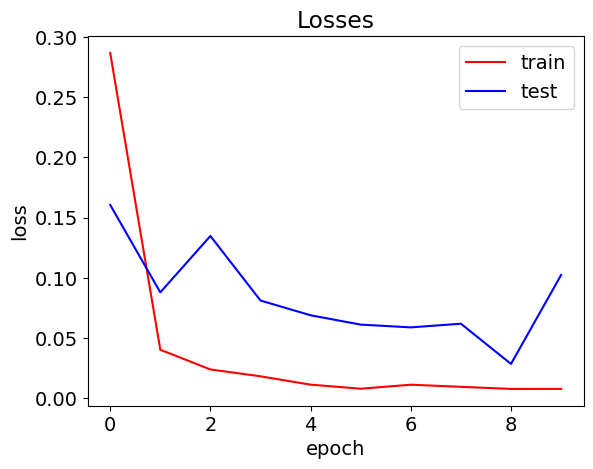

In [ ]:
plt.plot(np.arange(len(train_losses)), train_losses, label='train', color='r')
plt.plot(np.arange(len(total_loss_test)), total_loss_test, label='test', color='b')
plt.title('Losses')
plt.xlabel("epoch")
plt.ylabel('loss')
plt.legend()
plt.show()

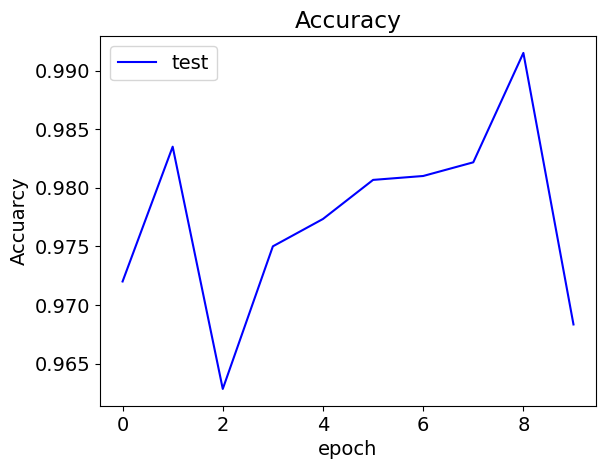

In [ ]:
plt.plot(np.arange(len(total_accuracy_test)), total_accuracy_test, label='test', color='b')
plt.title('Accuracy')
plt.xlabel("epoch")
plt.ylabel('Accuarcy')
plt.legend()
plt.show()

Если не брать последнюю эпоху, то на тестовом датасете лосс падает, точность растёт. Так как лосс резко не растёт, а точность резко не падает, то можно говорить, что модель учится стабильно и переобучения нет. Максимальная точность 0.9915 на 9 эпохе, на этой же эпохе и минимальный лосс

## Task 2(3 points)

Train the Multi-Format Contrastive Learning of Audio Representations model (implemented during the seminar) for at least 10 epochs. Plot the training loss curve and demonstrate that the loss has stabilized by the end of training.

Points:

- Training was conducted for at least 10 epochs — 1 point

- Loss has stabilized — 2 points

In [14]:
class block(nn.Module):
    def __init__(self, in_channels, out_channels, identity_downsample=None,stride=1):
        super(block, self).__init__()

        self.conv1 = nn.Conv1d(in_channels, out_channels, kernel_size=1, stride=1, padding=0)
        self.bn1 = nn.BatchNorm1d(out_channels)

        self.conv2 = nn.Conv1d(out_channels, out_channels, kernel_size=3, stride=stride, padding=1)
        self.bn2 = nn.BatchNorm1d(out_channels)

        self.identity_downsample = identity_downsample
        self.relu = nn.ReLU()


    def forward(self, x):
        identity = x

        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)

        x = self.conv2(x)
        x = self.bn2(x)

        if self.identity_downsample is not None:
            identity = self.identity_downsample(identity)

        x += identity
        x = self.relu(x)

        return x

class ResNet1D(nn.Module):
    # Resnet 18 [2, 2, 2, 2]
    def __init__(self, block):
        super(ResNet1D, self).__init__()
        # for resnet18
        layers = [2, 2, 2, 2]
        self.expansion = 1

        self.in_channels = 64
        self.conv1 = nn.Conv1d(1, self.in_channels, kernel_size=7, stride=2, padding=3, bias=False)
        self.bn1 = nn.BatchNorm1d(self.in_channels)
        self.relu = nn.ReLU()
        self.maxpool = nn.MaxPool1d(kernel_size=3, stride=2, padding=1)


        self.layer1 = self._make_layer(block, layers[0], 64, stride=1)
        self.layer2 = self._make_layer(block, layers[1], 128, stride=2)
        self.layer3 = self._make_layer(block, layers[2], 256, stride=2)
        self.layer4 = self._make_layer(block, layers[3], 512, stride=2)

        self.avgpool = nn.AdaptiveAvgPool1d(output_size=1)


        # size after avgpool = [32, 512, 1]

    def forward(self,x):
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.maxpool(x)

        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)

        x = self.avgpool(x)

        #x = x.reshape(x.shape[0], -1)
        #x = self.fc(x)

        return x



    def _make_layer(self, block, num_residual_block, out_channels, stride):
        identity_downsample = None
        layers = []

        if stride != 1:
            identity_downsample = nn.Sequential(nn.Conv1d(self.in_channels,
                                                out_channels*self.expansion,
                                                kernel_size=1,
                                                stride=stride,
                                                bias=False),
                                                nn.BatchNorm1d(out_channels*self.expansion),
                                                )
        layers.append(
            block(self.in_channels,out_channels, identity_downsample, stride)
        )
        self.in_channels = out_channels * self.expansion

        for i in range(1, num_residual_block):
            layers.append(block(self.in_channels,out_channels ))

        return nn.Sequential(*layers)



def CreateResNet1D():
    return ResNet1D(block)



class ResNet(nn.Module):
    # Resnet 18 [2, 2, 2, 2]
    def __init__(self, block, image_channels):
        super(ResNet, self).__init__()
        # for resnet18
        layers = [2, 2, 2, 2]
        self.expansion = 1

        self.in_channels = 64
        self.conv1 = nn.Conv2d(image_channels, self.in_channels, kernel_size=7, stride=2, padding=3, bias=False)
        self.bn1 = nn.BatchNorm2d(self.in_channels)
        self.relu = nn.ReLU()
        self.maxpool = nn.MaxPool2d(kernel_size=3, stride=2, padding=1)


        self.layer1 = self._make_layer(block, layers[0], 64, stride=1)
        self.layer2 = self._make_layer(block, layers[1], 128, stride=2)
        self.layer3 = self._make_layer(block, layers[2], 256, stride=2)
        self.layer4 = self._make_layer(block, layers[3], 512, stride=2)

        self.avgpool = nn.AdaptiveAvgPool2d((1,1))


    def forward(self,x):
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.maxpool(x)

        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)

        x = self.avgpool(x)

        return x



    def _make_layer(self, block, num_residual_block, out_channels, stride):
        identity_downsample = None
        layers = []

        if stride != 1:
            identity_downsample = nn.Sequential(nn.Conv2d(self.in_channels,
                                                out_channels*self.expansion,
                                                kernel_size=1,
                                                stride=stride,
                                                bias=False),
                                                nn.BatchNorm2d(out_channels*self.expansion),
                                                )
        layers.append(
            block(self.in_channels,out_channels, identity_downsample, stride)
        )
        self.in_channels = out_channels * self.expansion

        for i in range(1, num_residual_block):
            layers.append(block(self.in_channels,out_channels ))

        return nn.Sequential(*layers)



def CreateResNet2D(img_channels=3):
    return ResNet(block_resnet2d, image_channels=img_channels)

In [15]:
class Net(nn.Module):

    def __init__(self, img_channels = 1, num_classes = 35):
        super(Net, self).__init__()
        ####################### ENCODER ###################################
        self.resnet_1D = CreateResNet1D()
        self.resnet_2D = CreateResNet2D(img_channels=img_channels)

        self.output = nn.Sequential(
            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Linear(256, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Linear(256, 128)
        )

        ####################################################################

    def forward(self, input_spectogram, input_audio):
        """
            resnet2d and resnet1d output is [BS, 512, 1, 1]
            Output:
                - audio_emb, specs_emb used for contrastive loss
                - audio, spectograms used for Evaluation layer
                - output used for semi supervised - cross entropy
        """

        audio = self.resnet_1D(input_audio)
        audio = audio.squeeze()
        spectograms = self.resnet_2D(input_spectogram)
        spectograms = spectograms.squeeze()

        audio_emb = self.output(audio)
        specs_emb = self.output(spectograms)

        return audio_emb, specs_emb, audio, spectograms


class EvaluationHead(nn.Module):
    """
    Linear classifier head
    """
    def __init__(self, num_classes = 35):
        super(EvaluationHead, self).__init__()

        self.evaluation = nn.Sequential(
                    nn.Linear(512,num_classes)
        )

    def forward(self,x):
        x = self.evaluation(x)
        return x

In [16]:
def device_as(t1, t2):
   return t1.to(t2.device)

class ContrastiveLoss(nn.Module):
  def __init__(self, temperature=0.5):
    super().__init__()
    self.temperature = temperature

  def calc_similarity_batch(self, a, b):
    rep = torch.cat([a,b])
    return F.cosine_similarity(rep.unsqueeze(1), rep.unsqueeze(0), dim=2)

  def forward(self, proj_1, proj_2):
    batch_size = proj_1.shape[0]
    z_i = F.normalize(proj_1, p=2, dim=1)
    z_j = F.normalize(proj_2, p=2, dim=1)

    similarity_matrix = self.calc_similarity_batch(z_i, z_j)

    #######
    #aa#ab#
    #######
    #ba#bb#
    #######

    sim_ij = torch.diag(similarity_matrix, batch_size)
    sim_ji = torch.diag(similarity_matrix, -batch_size)

    positives = torch.cat([sim_ij, sim_ji])

    nominator = torch.exp(positives / self.temperature)

    mask = (~torch.eye(batch_size*2, batch_size*2).bool()).float()
    mask = device_as(mask, similarity_matrix)

    denominator = mask * torch.exp(similarity_matrix / self.temperature)
    all_losses = -torch.log(nominator / torch.sum(denominator, dim=1))
    loss = torch.sum(all_losses) / (2*batch_size)

    return loss

In [17]:
def create_task2(config):

  # Create model
  model = Net(img_channels=config.IMG_CHANNEL, num_classes = config.CLASSES).to(device)

  # Define the constrastive loss
  loss = ContrastiveLoss()

  #Define Melspectogram and STFT (Magnitude and Phase)
  mel_transform = LogMelSpectrogram(sample_rate=16000, n_fft=2048, hop_length=128, n_mels=128,f_min=40, f_max=8000, mel_scale="slaney").to(device)

  # Define the optimizer, the paper use
  optimizer = optim.Adam(model.parameters(), lr=config.LR, betas=(config.B1, config.B2), weight_decay=config.WEIGHT_DECAY)

  return model, loss, optimizer, mel_transform


def train_task2(model, closs, optimizer, trainloader, valloader, config, mel_transform, stft_trasform):
    train_losses = []
    total_accuracy_test = []
    total_loss_test = []
    scaler = torch.amp.GradScaler()

    for epoch in range(config.EPOCHS):
        progress_bar = tqdm(total=len(trainloader), unit='step')
        losses = []
        for audio,lab in trainloader:
            optimizer.zero_grad()

            audio = audio.to(device)

            # Create augmentation and spectograms!
            spectograms, audios = createModelInput(audio, mel_transform, None, augmentation=True)

            with torch.amp.autocast(device_type=str(device)):
                audio_emb, spect_emb, _, _ = model(spectograms, audios)
                loss = closs(audio_emb, spect_emb)



            # Calculate loss and backward
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            #progress bar stuff
            progress_bar.set_description(f"Epoch {epoch+1}/{config.EPOCHS}")
            progress_bar.set_postfix(loss=loss.item())  # Update the loss value
            progress_bar.update(1)

            # save loss to statistics
            losses.append(loss.item())

        # end for batch
        progress_bar.close()

        torch.save(model.state_dict(), f"models/model_{config.MODEL_TITLE}.pt")
        accuracy_test, loss_test = evaluationphase_task2(model, closs, valloader, config, mel_transform, stft_trasform)

        epoch_loss = np.mean(losses)
        train_losses.append(epoch_loss)
        total_accuracy_test.append(accuracy_test)
        total_loss_test.append(loss_test)

    return train_losses, total_accuracy_test, total_loss_test


def evaluationphase_task2(model, closs, val_loader, config, mel_transform, stft_trasform):

    model.eval()
    criterion = torch.nn.CrossEntropyLoss()
    # Get dataloaders
    # Freeze the gradients for model1
    for param in model.parameters():
        param.requires_grad = False

    def train_head(model, trainloader):

        # Create model
        modelEvaluation = None
        modelEvaluation = EvaluationHead(num_classes = config.CLASSES).to(device)

        # Define the optimizer, the paper use
        optimizer = optim.Adam(modelEvaluation.parameters(), lr=config.LR)


        for epoch in range(config.EVAL_EPOCHS):
            progress_bar = tqdm(total=len(trainloader), unit='step', leave=False)
            losses = []
            for audio,labels in trainloader:
                optimizer.zero_grad()
                audio = audio.to(device)
                # Create augmentation and spectograms!
                spectograms,audios = createModelInput(audio, mel_transform, stft_trasform, augmentation=False)

                labels_cat = torch.cat([labels, labels], dim = 0).to(device)

                # Use frozen encoder
                with torch.no_grad():
                    _, _, frozen_audio, frozen_spects = model(spectograms, audios)

                inputs = torch.cat([frozen_audio, frozen_spects], dim = 0)
                outputs = modelEvaluation(inputs)
                loss = criterion(outputs, labels_cat)

                # Calculate loss and backward
                loss.backward()
                optimizer.step()

                losses.append(loss.item())

                #progress bar stuff
                progress_bar.set_description(f"Head tuning epoch {epoch+1}/{config.EVAL_EPOCHS}")
                progress_bar.set_postfix(loss=np.mean(losses))  # Update the loss value
                progress_bar.update(1)

            # end for batch
            progress_bar.close()


        return modelEvaluation

    def evaluation(model, model_eval, dataloader):
        model_eval.eval()
        progress_bar = tqdm(total=len(dataloader), unit='step')
        val_loss = 0.0
        total = 0
        correct = 0
        with torch.no_grad():
            for i, (audio,labels) in enumerate(dataloader):

                audio = audio.to(device)
                spectograms,audios = createModelInput(audio, mel_transform, stft_trasform,  augmentation=False)
                labels_cat = torch.cat([labels, labels], dim = 0).to(device)

                # Use frozen encoder
                _, _, frozen_audio, frozen_spects = model(spectograms, audios)
                inputs = torch.cat([frozen_audio, frozen_spects], dim = 0)
                outputs = model_eval(inputs)
                _, predicated = torch.max(outputs.data, 1)
                total += labels_cat.size(0)
                batch_loss = criterion(outputs, labels_cat)
                val_loss += batch_loss.item() * labels_cat.size(0)

                correct += (predicated == labels_cat).sum().item()

                #progress bar stuff
                progress_bar.set_description(f"Evaluation {i+1}/{len(dataloader)}")
                progress_bar.update(1)

            # end for batch
            progress_bar.close()

        return correct/total, val_loss/total


    model_ = train_head(model, train_loader)
    accuracy_test, loss_test = evaluation(model, model_, val_loader)
    print(f"Accuracy on validation: {accuracy_test}")
    print(f"Loss on validation: {loss_test}")
    model.train()
    for param in model.parameters():
        param.requires_grad = True

    return accuracy_test, loss_test

In [ ]:
hyperparameters = {
        'LR': 3e-4,
        'WEIGHT_DECAY': 1e-6,
        'B1':0.9,
        'B2':0.999,
        'EPOCHS': 10,
        'BATCH_SIZE': 128,
        'IMG_CHANNEL': 1,
        'CLASSES': 10,
        'EVAL_BATCH':128,
        'EVAL_EPOCHS':1,
        'MODEL_TITLE': 'contrastive'
}
config = DictConfig(hyperparameters)

# Init dataloaders
train_loader = DataLoader(train_ds, batch_size=config.BATCH_SIZE, shuffle=True, collate_fn=collate)
val_loader  = DataLoader(valid_ds,  batch_size=config.EVAL_BATCH, shuffle=False, collate_fn=collate)

#make the model, data and optimization problem
model2, loss2, optimizer2, mel_transform2 = create_task2(config)

#train the model
train_losses2, total_accuracy_test2, total_loss_test2 = train_task2(model2, loss2, optimizer2, train_loader, val_loader, config, mel_transform2, None)

  0%|          | 0/188 [00:00<?, ?step/s]

  0%|          | 0/188 [00:00<?, ?step/s]

  0%|          | 0/47 [00:00<?, ?step/s]

Accuracy on validation: 0.5401666666666667
Loss on validation: 1.5480410397847493


  0%|          | 0/188 [00:00<?, ?step/s]

...

Accuracy on validation: 0.6243333333333333
Loss on validation: 1.354015999476115


  0%|          | 0/188 [00:00<?, ?step/s]

  0%|          | 0/188 [00:00<?, ?step/s]

  0%|          | 0/47 [00:00<?, ?step/s]

Accuracy on validation: 0.6388333333333334
Loss on validation: 1.2997403326034547


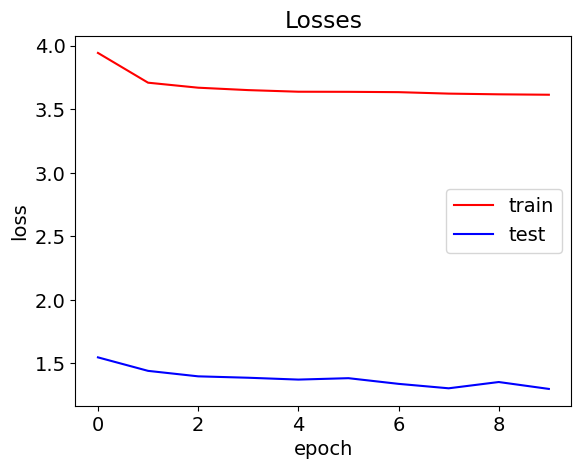

In [ ]:
plt.plot(np.arange(len(train_losses2)), train_losses2, label='train', color='r')
plt.plot(np.arange(len(total_loss_test2)), total_loss_test2, label='test', color='b')
plt.title('Losses')
plt.xlabel("epoch")
plt.ylabel('loss')
plt.legend()
plt.show()

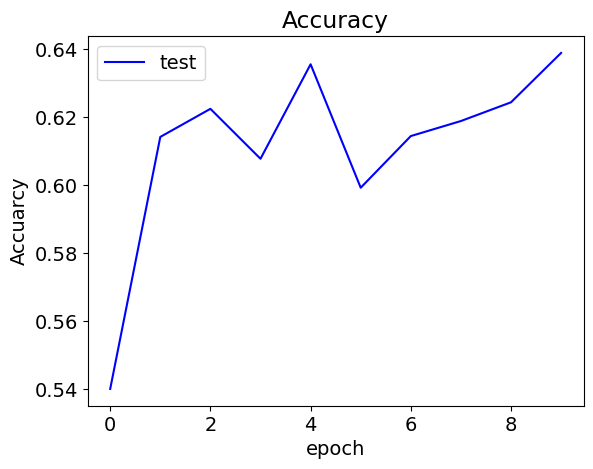

In [ ]:
plt.plot(np.arange(len(total_accuracy_test2)), total_accuracy_test2, label='test', color='b')
plt.title('Accuracy')
plt.xlabel("epoch")
plt.ylabel('Accuarcy')
plt.legend()
plt.show()

## Task 3(5 points)

Replace the InfoNCE loss in the Multi-Format Contrastive Learning of Audio Representations framework with a Non-Contrastive Learning method.

Motivate the choice of the method based on the literature, implement it in a way consistent with the original paper or justify the introduced modifications, and train the model for at least 30 epochs or until the loss stabilizes. Present the training curves to support your conclusions.

You can try one of the following NCL methods:
- BYOL([paper](https://arxiv.org/pdf/2006.07733))
- SimSiam([paper](https://arxiv.org/pdf/2011.10566))
- Barlow Twins([paper](https://arxiv.org/pdf/2103.03230))
- VicReg([paper](https://arxiv.org/pdf/2105.04906))

Points:

- An analysis of the selected method was conducted based on the literature: training speed, optimal batch size, number of hyperparameters, and results on downstream tasks (the domain and specific tasks are not critical) — +1 point

- A method not listed here was selected (BYOL, SimSiam, Barlow Twins, VicReg) — +1 point

- The code is implemented correctly and aligns with the article (without unnecessary modules, projectors, or predictors, unless specified by the authors), or a well-reasoned justification for the changes is provided — +2 points (simply works: +1 point)

- The model has been trained for at least 30 epochs or until the loss function stabilizes — +1 point




Будем использовать метод DINO [тык](https://arxiv.org/pdf/2104.14294)

Так как этот метод NCL, то DINO не использует отрицательные примеры. В данном методе используются две сети: student приближает распределение выходов teacher для разных представлений одного объекта.

Сеть student обновляется градиентным спуском, а сеть teacher обновляется с помощью EMA (экспоненциального скользящего среднего), используя параметры student. Чтобы данные не схлопнулись применяются центрирование выходов сети teacher и temperature sharpening (не знаю, как это по русски описать)). Сеть teacher формирует целевое распределение, а сеть student минимизирует кросс-энтропию между этим распределением и собственным предсказанием.

Скорость обучения в практических условиях оказалась быстрее, чем у метода InfoNCE, но это всё зависит от выбранных параметров.

В данной работе используется batch size 64. В оригинальной статье обучение проводилось на более мощных ресурсах, поэтому оригинальные параметры тяжело перенести в colab.

В DINO есть следующие параметры: learning rate, weight decay, температуры student и teacher, momentum teacher, momentum центрирования. В данной работе: student temperature 0.1, teacher temperature 0.04, center momentum 0.9 и EMA momentum teacher, изменяющийся по расписанию.

В оригинальной статье DINO был использован для задач компьютерного зрения, но его можно перенести на аудио, использовав оригинальное wav представление и mel-спектрограмму.

In [26]:
class DINOHead(nn.Module):
    def __init__(self, in_dim=512, hidden_dim=256, bottleneck_dim=256, out_dim=1024):
        super().__init__()

        # MLP-голова
        self.mlp = nn.Sequential(
            nn.Linear(in_dim, hidden_dim),
            nn.GELU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.GELU(),
            nn.Linear(hidden_dim, bottleneck_dim)
        )

        # Нормализуем веса перед последним слоем
        self.last_layer = nn.utils.parametrizations.weight_norm(
            nn.Linear(bottleneck_dim, out_dim, bias=False)
        )

        with torch.no_grad():
            self.last_layer.parametrizations.weight.original0.fill_(1.0)

        self.last_layer.parametrizations.weight.original0.requires_grad = False

    def forward(self, x):
        x = self.mlp(x)
        x = F.normalize(x, dim=-1)
        return self.last_layer(x)


class DINOEncoder(nn.Module):
    def __init__(self, img_channels=1, out_dim=1024):
        super().__init__()

        self.resnet_1D = CreateResNet1D()
        self.resnet_2D = CreateResNet2D(img_channels=img_channels)

        self.output = DINOHead(in_dim=512, out_dim=out_dim)

    def forward(self, input_spectrogram, input_audio):
        # [B, 512, 1] -> [B, 512]
        audio_features = self.resnet_1D(input_audio).flatten(1)
        spec_features = self.resnet_2D(input_spectrogram).flatten(1)

        audio_logits = self.output(audio_features)
        spec_logits = self.output(spec_features)

        return audio_logits, spec_logits, audio_features, spec_features


class Net(nn.Module):
    def __init__(self, img_channels=1, num_classes=10, out_dim=1024):
        super().__init__()

        # 2 модели - student обучается, teacher - не обновляется с помощью градиентного спуска
        self.student = DINOEncoder(img_channels=img_channels, out_dim=out_dim)

        self.teacher = DINOEncoder(img_channels=img_channels, out_dim=out_dim)
        self.teacher.load_state_dict(self.student.state_dict())

        for p in self.teacher.parameters():
            p.requires_grad = False

        self.teacher.eval()

    def forward(self, input_spectrogram, input_audio):
        return self.student(input_spectrogram, input_audio)

    @torch.no_grad()
    def teacher_forward(self, input_spectrogram, input_audio):
        return self.teacher(input_spectrogram, input_audio)

    @torch.no_grad()
    def update_teacher(self, momentum):
        # обновляем веса через EMA - экспоненциальное скользящее среднее
        for student_p, teacher_p in zip(self.student.parameters(), self.teacher.parameters()):
            teacher_p.copy_(momentum * teacher_p + (1.0 - momentum) * student_p)

        # Синхронизируем буферы
        for student_b, teacher_b in zip(self.student.buffers(), self.teacher.buffers()):
            teacher_b.copy_(student_b)

        self.teacher.eval()

# Лосс из статьи
class DINOLoss(nn.Module):
    def __init__(self, out_dim=1024, student_temp=0.1, teacher_temp=0.07, center_momentum=0.9):
        super().__init__()

        self.student_temp = student_temp
        self.teacher_temp = teacher_temp
        self.center_momentum = center_momentum

        # Используем буфер, чтобы не обучать этот параметр
        self.register_buffer("center", torch.zeros(1, out_dim))

    def forward(self, student_outputs, teacher_outputs):
        teacher_probs = [F.softmax((t.detach() - self.center) / self.teacher_temp, dim=-1) for t in teacher_outputs]
        student_log_probs = [F.log_softmax(s / self.student_temp, dim=-1) for s in student_outputs]

        total_loss = 0.0
        n_terms = 0

        for i, target in enumerate(teacher_probs):
            for j, prediction in enumerate(student_log_probs):
                if i == j:
                    continue

                cross_entropy = -torch.sum(target * prediction, dim=-1).mean()
                total_loss = total_loss + cross_entropy
                n_terms += 1

        loss = total_loss / n_terms

        with torch.no_grad():
            batch_center = torch.cat([t.detach() for t in teacher_outputs], dim=0).mean(dim=0, keepdim=True)
            self.center.copy_(self.center_momentum * self.center + (1.0 - self.center_momentum) * batch_center)

        return loss

In [32]:
hyperparameters = {
    "LR": 1e-4,
    "WEIGHT_DECAY": 1e-6,
    "B1": 0.9,
    "B2": 0.999,
    "EPOCHS": 30,
    "BATCH_SIZE": 64,
    "IMG_CHANNEL": 1,
    "CLASSES": 10,
    "DINO_OUT_DIM": 1024,
    "STUDENT_TEMP": 0.1,
    "TEACHER_TEMP": 0.04,
    "CENTER_MOMENTUM": 0.9,
    "MODEL_TITLE": "dino_audio_resnets_exp1"
}

config = DictConfig(hyperparameters)
train_loader = DataLoader(train_ds, batch_size=config.BATCH_SIZE, shuffle=True, collate_fn=collate)
val_loader = DataLoader(valid_ds, batch_size=config.BATCH_SIZE, shuffle=False, collate_fn=collate)

model = Net(img_channels=config.IMG_CHANNEL, num_classes=config.CLASSES, out_dim=config.DINO_OUT_DIM).to(device)
criterion = DINOLoss(out_dim=config.DINO_OUT_DIM, student_temp=config.STUDENT_TEMP, teacher_temp=config.TEACHER_TEMP, center_momentum=config.CENTER_MOMENTUM).to(device)
mel_transform = LogMelSpectrogram(sample_rate=16000, n_fft=2048, hop_length=128, n_mels=128,f_min=40, f_max=8000, mel_scale="slaney").to(device)
optimizer = optim.Adam(model.parameters(), lr=config.LR, betas=(config.B1, config.B2), weight_decay=config.WEIGHT_DECAY)
scaler = torch.amp.GradScaler()

train_losses = []

for epoch in range(config.EPOCHS):
    model.train()
    model.teacher.eval()

    epoch_losses = []

    progress = epoch / max(config.EPOCHS - 1, 1)
    teacher_momentum = 1.0 - (1.0 - 0.996) * (1.0 + math.cos(math.pi * progress)) / 2.0

    progress_bar = tqdm(train_loader, desc=f"Epoch {epoch + 1}/{config.EPOCHS}")

    for audio, _labels in progress_bar:
        audio = audio.to(device)
        optimizer.zero_grad(set_to_none=True)

        spec1, wav1 = createModelInput(audio, mel_transform, None, augmentation=True)
        spec2, wav2 = createModelInput(audio, mel_transform, None, augmentation=True)

        with torch.amp.autocast(device_type=str(device)):
            s1 = model(spec1, wav1)
            s2 = model(spec2, wav2)

            student_outputs = [
                s1[0], s1[1],
                s2[0], s2[1]
            ]

            with torch.no_grad():
                t1 = model.teacher_forward(spec1, wav1)
                t2 = model.teacher_forward(spec2, wav2)

                teacher_outputs = [
                    t1[0], t1[1],
                    t2[0], t2[1]
                ]

            loss = criterion(student_outputs, teacher_outputs)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        model.update_teacher(teacher_momentum)

        loss_value = loss.detach().item()
        epoch_losses.append(loss_value)

        progress_bar.set_postfix(loss=f"{loss_value:.4f}", teacher_m=f"{teacher_momentum:.4f}")

    epoch_loss = float(np.mean(epoch_losses))
    train_losses.append(epoch_loss)

    print(f"Epoch {epoch + 1}/{config.EPOCHS}: DINO loss = {epoch_loss:.5f}")

    torch.save(model.state_dict(), f"models/model_{config.MODEL_TITLE}.pt")

Epoch 1/30:   0%|          | 0/375 [00:00<?, ?it/s]

Epoch 1/30: DINO loss = 6.91703


Epoch 2/30:   0%|          | 0/375 [00:00<?, ?it/s]

Epoch 2/30: DINO loss = 6.92408


Epoch 3/30:   0%|          | 0/375 [00:00<?, ?it/s]

...

Epoch 28/30: DINO loss = 3.33787


Epoch 29/30:   0%|          | 0/375 [00:00<?, ?it/s]

Epoch 29/30: DINO loss = 3.47029


Epoch 30/30:   0%|          | 0/375 [00:00<?, ?it/s]

Epoch 30/30: DINO loss = 3.42698


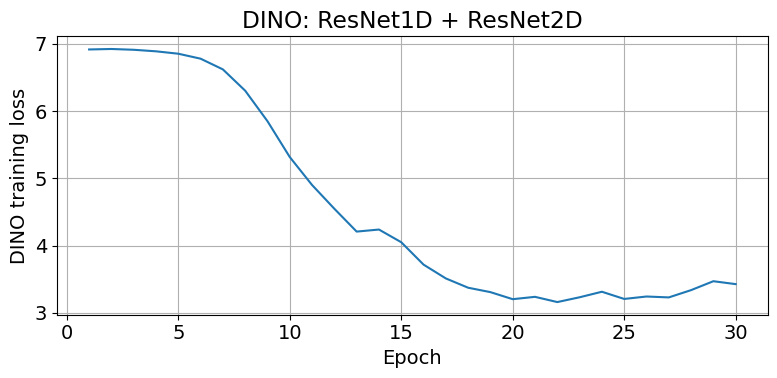

In [33]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(train_losses) + 1), train_losses)
plt.xlabel("Epoch")
plt.ylabel("DINO training loss")
plt.title("DINO: ResNet1D + ResNet2D")
plt.grid(True)
plt.tight_layout()
plt.show()

Теперь обучим логистическую регрессию, чтобы посмотреть точность классификации. Для этого прогоним данные через модель и сконкатенируем выходы resnet1d и resnet2d

In [35]:
def extract_features(loader):
    model.eval()

    features_list = []
    labels_list = []

    with torch.no_grad():
        for audio, labels in loader:
            audio = audio.to(device)

            spec, wav = createModelInput(audio, mel_transform, None, augmentation=False)
            _, _, audio_features, spec_features = model(spec, wav)

            combined_features = torch.cat([audio_features, spec_features], dim=1)
            features_list.append(combined_features.cpu().numpy())
            labels_list.append(torch.as_tensor(labels).cpu().numpy())

    return np.concatenate(features_list, axis=0), np.concatenate(labels_list, axis=0)


X_train, y_train = extract_features(train_loader)
X_valid, y_valid = extract_features(val_loader)

print("Train features:", X_train.shape)
print("Validation features:", X_valid.shape)

Train features: (24000, 1024)
Validation features: (6000, 1024)


In [38]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

classifier = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000)
)

classifier.fit(X_train, y_train)

y_pred = classifier.predict(X_valid)
accuracy = accuracy_score(y_valid, y_pred)

print(f"Accuracy: {accuracy * 100:.2f}%")
print("\nClassification report:")
print(classification_report(y_valid, y_pred, zero_division=0))

Accuracy: 93.28%

Classification report:
              precision    recall  f1-score   support

           0       0.95      0.95      0.95       600
           1       0.79      0.98      0.88       600
           2       0.93      0.99      0.96       600
           3       0.94      0.95      0.95       600
           4       0.98      0.96      0.97       600
           5       0.98      0.86      0.91       600
           6       0.99      0.97      0.98       600
           7       0.99      0.91      0.95       600
           8       0.95      1.00      0.97       600
           9       0.85      0.75      0.80       600

    accuracy                           0.93      6000
   macro avg       0.94      0.93      0.93      6000
weighted avg       0.94      0.93      0.93      6000



Получаем accuracy 93.28%. Можно заметить, что модель хуже различает цифры 1 и 9 по метрике f1. Можно предположить, что это связано с тем, что фонетически эти цифры заканчиваются на n

### Вывод

Модель обучалась на 30 эпохах. batch size 64. По графику можно заметить, что training loss уменьшился с 6.917 до 3.427 в последней. Минимальное значение 3.160 на 22 эпохе. Примерно до 16 эпохи loss постепенно уменьшался, а затем до 30 эпохи незначительно уменьшался, что может говорить о том, что он вышел на плато.

Был обучен линейный классификатор на основе сконкатенированных признаков resnet1d и resnet2d. Точность составила 93.28%. Можно сказать, что представления, которые были получены с помощью DINO уловили фонетические представления цифр и могут быть полезны.

На основе f1-score, как уже было замечено ранее, хуже всего различимы цифры 1 и 9, что возможно связано с их фонетической структурой.

## Task 4(2 points)

Evaluate and compare three training setups on the validation subset:

1. Supervised training

2. InfoNCE (contrastive learning)

3. Non-Contrastive Learning (NCL)

Use either the 2D or 1D encoder—or combine their embeddings.
Identify which setup performs best and explain why it outperforms the others.

Points:

- A numerical comparison of the metrics for the three approaches (supervised, contrastive, NCL) was conducted — 1 point

- In addition to the comparison, a substantive explanation was provided as to why the chosen approach yielded the best results — 1 point

Сравнение результатов
| Подход | Лучшая validation accuracy |
|--------|----------------------------|
|Supervised learning|99,15%|
|InfoNCE|63,88%|
|DINO (NCL)|93,28%|

Лучший результат на валидационном датасете по accuracy показала модель supervised learning — 99.15%. InfoNCE - 63.88%, DINO - 93.28% для объединённых признаков с помощью логистической регрессии.

Supervised learning показал наилучшее качество, так как был направлен на решение конкретной задачи. Также во время обучения используются метки классов, что является полезным для модели, позволяя ей эффективнее обучаться для данной задачи.

Результат InfoNCE существенно ниже. Контрастивное обучение направлено на сближение представлений разных аугментаций одного объекта и разделение представлений различных объектов. Такой метод позволяет получать не только решение конкретной задачи, но и получать внутренне представление входных данных.

DINO показал более высокую accuracy по сравнению с InfoNCE. Механизм самодистилляции позволяет сети student обучаться на распределениях, сформированных сети teacher. accuracy 93.28% говорит о том, что модель смогла извлечь информативные признаки. Качество DINO оказалось немного ниже результата supervised, что логично, так как supervised-модель обучается под конкретную задачу, а NCL метод позволяет учиться без меток и получать некие представления, а затем дообучаться для конкретной задачи.

Важно сказать, что необходимо учитывать различия в оценке моделей. Supervised-модель оценивалась непосредственно по точности классификации, для InfoNCE использовалась evaluation head, а для DINO — логистическая регрессия на объединённых признаках сырых wav и спектрограмм.

В проведённых экспериментах supervised learning показал наилучшую accuracy, а метод DINO оказался более перспективным, чем InfoNCE. Результаты показывают, что self-supervised методы способны формировать полезные представления аудиосигналов без прямого использования меток классов.